# Reconocimiento de dígitos con MNIST

## Objetivo
Comparar dos formas de reconocer los dígitos del 0 al 9: un perceptrón multicapa (MLP) que recibe características HOG y una red convolucional (CNN) que recibe las imágenes. Este notebook es un trabajo independiente para practicar los ejercicios.

**Cómo usarlo:** ejecuta las celdas en orden. La primera descarga de MNIST necesita conexión a internet. Si falta alguna librería en tu entorno, instala `tensorflow`, `scikit-image`, `scikit-learn` y `matplotlib` en el entorno seleccionado. El entrenamiento puede tardar varios minutos.

## 1. Preparar los datos
MNIST contiene imágenes de 28 × 28 píxeles. Reservamos el conjunto de prueba para la evaluación final. Para que la comparación sea más sencilla y rápida, ambos modelos utilizan las mismas 6.000 imágenes iniciales del conjunto de entrenamiento; de ellas se reserva un 10 % para validación.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from skimage.feature import hog
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

tf.keras.utils.set_random_seed(42)
(imagenes_entrenamiento, etiquetas_entrenamiento), (imagenes_prueba, etiquetas_prueba) = tf.keras.datasets.mnist.load_data()

cantidad = 6000
imagenes_entrenamiento = imagenes_entrenamiento[:cantidad]
etiquetas_entrenamiento = etiquetas_entrenamiento[:cantidad]
print('Entrenamiento y validación:', imagenes_entrenamiento.shape, etiquetas_entrenamiento.shape)
print('Prueba:', imagenes_prueba.shape, etiquetas_prueba.shape)

Entrenamiento y validación: (6000, 28, 28) (6000,)
Prueba: (10000, 28, 28) (10000,)


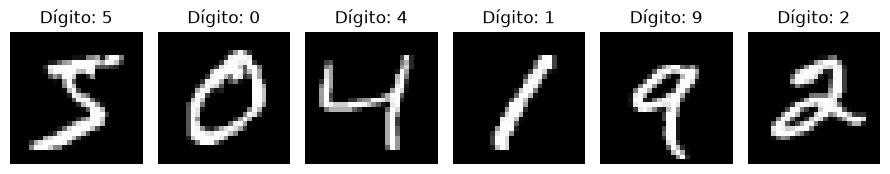

In [12]:
fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for ax, imagen, etiqueta in zip(axes, imagenes_entrenamiento[:6], etiquetas_entrenamiento[:6]):
    ax.imshow(imagen, cmap='gray')
    ax.set_title(f'Dígito: {etiqueta}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Ejercicio 1: HOG + MLP
HOG (histograma de gradientes orientados) resume los bordes y las direcciones de los trazos. Convertimos cada imagen en un vector de características y se lo pasamos a un MLP, una red de capas densas. La misma transformación debe aplicarse a las imágenes de entrenamiento y de prueba.

In [13]:
def extraer_hog(imagenes):
    return np.array([
        hog(imagen / 255.0, orientations=8, pixels_per_cell=(7, 7),
            cells_per_block=(2, 2), block_norm='L2-Hys')
        for imagen in imagenes
    ], dtype=np.float32)

hog_entrenamiento = extraer_hog(imagenes_entrenamiento)
hog_prueba = extraer_hog(imagenes_prueba)
print('Vectores de entrenamiento:', hog_entrenamiento.shape)
print('Vectores de prueba:', hog_prueba.shape)
assert len(hog_entrenamiento) == len(etiquetas_entrenamiento)
assert len(hog_prueba) == len(etiquetas_prueba)

Vectores de entrenamiento: (6000, 288)
Vectores de prueba: (10000, 288)


In [14]:
mlp = models.Sequential([
    layers.Input(shape=(hog_entrenamiento.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
])
mlp.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
mlp.summary()
historial_mlp = mlp.fit(hog_entrenamiento, etiquetas_entrenamiento,
                        epochs=5, batch_size=128, validation_split=0.1)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,282 (149.54 KB)

 Trainable params: 38,282 (149.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6443 - loss: 1.6752 - val_accuracy: 0.8433 - val_loss: 1.0703
Epoch 2/5
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8802 - loss: 0.7215 - val_accuracy: 0.8950 - val_loss: 0.5243
Epoch 3/5
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9100 - loss: 0.4161 - val_accuracy: 0.9067 - val_loss: 0.3660
Epoch 4/5
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9265 - loss: 0.3106 - val_accuracy: 0.9167 - val_loss: 0.3006
Epoch 5/5
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9344 - loss: 0.2642 - val_accuracy: 0.9183 - val_loss: 0.2659


En este ejercicio utilicé el conjunto de datos MNIST para reconocer números escritos a mano. Seleccioné 6.000 imágenes para entrenamiento y validación y reservé 10.000 para prueba.

Primero apliqué HOG para extraer información sobre los bordes de cada imagen. Cada imagen se convirtió en un vector de 288 características. Después entrené un MLP con una capa oculta de 128 neuronas y una capa de salida de 10 neuronas, una por cada dígito.

Después de 5 épocas, el modelo alcanzó una precisión de validación del 91,83 %. La evaluación final con imágenes de prueba aparece más adelante.

## 3. Ejercicio 2: CNN
Una CNN recibe la imagen en vez del vector HOG y aprende filtros para detectar patrones. Dividimos los píxeles entre 255 para llevarlos al rango de 0 a 1 y añadimos una dimensión de canal, porque las imágenes son en escala de grises.

In [15]:
cnn_entrenamiento = imagenes_entrenamiento.astype('float32')[..., np.newaxis] / 255.0
cnn_prueba = imagenes_prueba.astype('float32')[..., np.newaxis] / 255.0
print('Imágenes de entrenamiento:', cnn_entrenamiento.shape)
print('Imágenes de prueba:', cnn_prueba.shape)

cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn.summary()
historial_cnn = cnn.fit(cnn_entrenamiento, etiquetas_entrenamiento,
                        epochs=5, batch_size=128, validation_split=0.1)

Imágenes de entrenamiento: (6000, 28, 28, 1)
Imágenes de prueba: (10000, 28, 28, 1)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6902 - loss: 1.0874 - val_accuracy: 0.9017 - val_loss: 0.3293
Epoch 2/5
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9146 - loss: 0.2956 - val_accuracy: 0.9433 - val_loss: 0.1929
Epoch 3/5
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9450 - loss: 0.1871 - val_accuracy: 0.9517 - val_loss: 0.1482
Epoch 4/5
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9598 - loss: 0.1376 - val_accuracy: 0.9517 - val_loss: 0.1365
Epoch 5/5
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9683 - loss: 0.1045 - val_accuracy: 0.9567 - val_loss: 0.1277


En el segundo ejercicio utilicé una red neuronal convolucional para clasificar imágenes de dígitos de MNIST. A diferencia del primer ejercicio, la CNN recibe las imágenes y aprende filtros para detectar sus características.

Antes del entrenamiento, normalicé los píxeles entre 0 y 1 y añadí una dimensión de canal porque las imágenes están en escala de grises. La red contiene dos capas convolucionales, capas de reducción de tamaño y capas densas que producen una predicción entre los dígitos 0 y 9.

Entrené la red durante cinco épocas. Al finalizar, obtuvo un 96,83 % de precisión durante el entrenamiento y un 95,67 % en validación. En esta ejecución, la precisión de validación fue mayor que la del modelo HOG + MLP. La comparación con imágenes de prueba aparece a continuación.

## 4. Evaluación y comparación
Evaluamos ambos modelos sobre las mismas 10.000 imágenes de prueba. La precisión es la proporción de predicciones correctas. En la matriz de confusión, las filas indican los valores reales y las columnas las predicciones.


HOG + MLP — precisión: 0.9405
              precision    recall  f1-score   support

           0       0.93      0.98      0.96       980
           1       0.98      0.97      0.98      1135
           2       0.93      0.94      0.93      1032
           3       0.96      0.94      0.95      1010
           4       0.95      0.95      0.95       982
           5       0.95      0.94      0.95       892
           6       0.97      0.95      0.96       958
           7       0.94      0.89      0.91      1028
           8       0.92      0.92      0.92       974
           9       0.89      0.93      0.91      1009

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



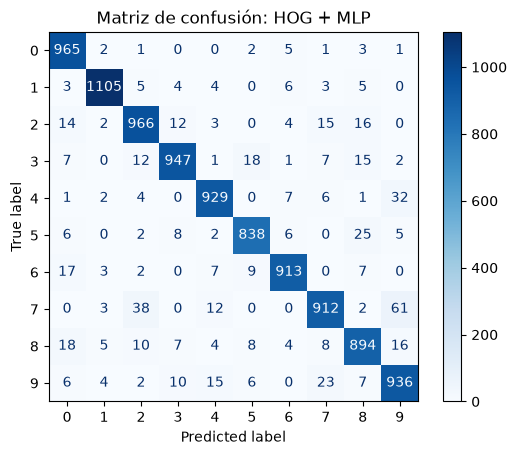


CNN — precisión: 0.9624
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       980
           1       0.98      0.99      0.99      1135
           2       0.96      0.97      0.96      1032
           3       0.94      0.98      0.96      1010
           4       0.95      0.98      0.97       982
           5       0.98      0.94      0.96       892
           6       0.98      0.94      0.96       958
           7       0.98      0.93      0.95      1028
           8       0.96      0.94      0.95       974
           9       0.95      0.96      0.95      1009

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000



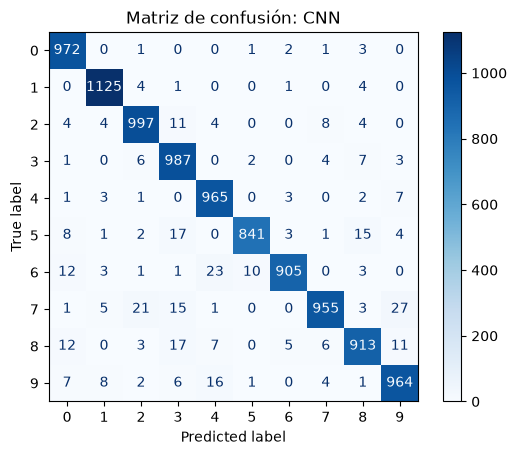

In [16]:
predicciones_mlp = np.argmax(mlp.predict(hog_prueba, verbose=0), axis=1)
predicciones_cnn = np.argmax(cnn.predict(cnn_prueba, verbose=0), axis=1)

for nombre, predicciones in [('HOG + MLP', predicciones_mlp), ('CNN', predicciones_cnn)]:
    print(f'\n{nombre} — precisión: {accuracy_score(etiquetas_prueba, predicciones):.4f}')
    print(classification_report(etiquetas_prueba, predicciones, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(etiquetas_prueba, predicciones, cmap='Blues')
    plt.title(f'Matriz de confusión: {nombre}')
    plt.show()

## 5. Mis conclusiones
Evalué los modelos con 10.000 imágenes de prueba que no se utilizaron para el entrenamiento. El modelo HOG + MLP obtuvo una precisión del 94,05 %, mientras que la CNN alcanzó un 96,24 %. Por tanto, en esta ejecución la CNN acertó 219 imágenes más.

La matriz de confusión permite ver en qué dígitos se equivoca cada modelo. Aunque la CNN obtuvo mejor precisión general, tuvo más dificultad para reconocer algunos sietes: su recall para ese dígito fue aproximadamente del 93 %. El MLP utiliza características HOG calculadas previamente, mientras que la CNN aprende filtros directamente a partir de las imágenes.

Como posible mejora, podría probar más imágenes de entrenamiento o cambiar las épocas y la arquitectura, comparando después los resultados.